
## Data Cleaning

This notebook focuses on assessing and cleaning the original logistics and supply chain dataset. We will investigate missing values, duplicate records, data types, invalid values, and potential outliers.


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pandas as pd

from google.colab import drive
drive.mount('/content/drive')

# Load original dataset

path = '/content/drive/MyDrive/INSY_6500/logistics_supply_chain.csv'

df = pd.read_csv(path)

# Create a separate copy for cleaning
df_clean = df.copy()

df_clean.head()

#TO DO: could make this a function


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,shipment_id,tracking_number,order_id,customer_id,customer_name,shipment_type,carrier,status,origin_city,origin_country,...,delivery_attempts,signature_required,customer_satisfaction_score,delay_reason,damage_reported,claim_filed,claim_amount_eur,co2_emissions_kg,is_international,created_at
0,SHP-202300000,TRK564397239452,ORD-1037076,CUST-777297,Max Mensah,Next Day,UPS,Out for Delivery,Berlin,Deutschland,...,5,False,NaN,Weather,False,True,0.00,83.21,True,2023-10-10 02:48:00
1,SHP-202300001,TRK693936529454,ORD-1083283,CUST-792581,Anna Becker,Standard,DPD,Lost,Dusseldorf,GERMANY,...,1,True,NaN,Customs Delay,False,True,0.00,6.82,False,2023-06-07 04:38:00
2,SHP-202300002,TRK934047434283,ORD-5222356,CUST-252305,Leon Schmidt,Standard,FedEx,Delivered,Essen,Germany,...,1,False,3.0,Customs Delay,False,False,0.00,29.85,False,2023-07-17 23:37:00
3,SHP-202300003,TRK249392322429,ORD-4467160,CUST-334941,Thomas Mensah,Standard,Amazon Logistics,Out for Delivery,Cologne,GERMANY,...,2,False,4.0,Traffic,True,False,703.96,84.77,False,2023-01-08 21:43:00
4,SHP-202300004,TRK275611159480,ORD-8925636,CUST-566318,David Wolf,Next Day,Amazon Logistics,Attempted,Bremen,DE,...,4,False,2.0,Traffic,True,False,0.00,54.08,False,2023-03-22 15:27:00


### Checking for Duplicate Records

In [31]:
# Check for duplicated rows

print("Number of duplicate rows:", df_clean.duplicated().sum())

# Check for duplicate shipment IDs

print(
    "Number of duplicate shipment IDs:",
    df_clean["shipment_id"].duplicated().sum()
)


Number of duplicate rows: 714
Number of duplicate shipment IDs: 714


In [32]:

# Investigate Duplicates: Display records with duplicate shipment IDs

duplicate_shipments = df_clean[
    df_clean["shipment_id"].duplicated(keep=False)
].sort_values("shipment_id")

duplicate_shipments.head(20)


,shipment_id,tracking_number,order_id,customer_id,customer_name,shipment_type,carrier,status,origin_city,origin_country,...,delivery_attempts,signature_required,customer_satisfaction_score,delay_reason,damage_reported,claim_filed,claim_amount_eur,co2_emissions_kg,is_international,created_at
37,SHP-202300037,TRK242574414015,ORD-5430852,CUST-498208,Andreas Wolf,Same Day,DPD,Returned,Hamburg,DE,...,3,False,2.0,Traffic,True,True,0.00,49.98,False,2023-02-28 16:39:00
51594,SHP-202300037,TRK242574414015,ORD-5430852,CUST-498208,Andreas Wolf,Same Day,DPD,Returned,Hamburg,DE,...,3,False,2.0,Traffic,True,True,0.00,49.98,False,2023-02-28 16:39:00
116,SHP-202300116,TRK229706686139,ORD-9901233,CUST-758927,Sarah Osei,Express,DHL,Attempted,Frankfurt,GERMANY,...,2,False,4.0,NaN,True,True,0.00,10.16,False,2023-03-27 05:36:00
51317,SHP-202300116,TRK229706686139,ORD-9901233,CUST-758927,Sarah Osei,Express,DHL,Attempted,Frankfurt,GERMANY,...,2,False,4.0,NaN,True,True,0.00,10.16,False,2023-03-27 05:36:00
131,SHP-202300131,TRK593755798708,ORD-9320572,CUST-607221,Emma Richter,International,FedEx,In Transit,Dresden,Deutschland,...,5,False,2.0,Recipient Not Available,True,False,0.00,75.13,True,2023-02-20 11:15:00
51560,SHP-202300131,TRK593755798708,ORD-9320572,CUST-607221,Emma Richter,International,FedEx,In Transit,Dresden,Deutschland,...,5,False,2.0,Recipient Not Available,True,False,0.00,75.13,True,2023-02-20 11:15:00
142,SHP-202300142,TRK654066048080,ORD-2536247,CUST-286077,Christina Becker,Standard,DHL,DELIVERED,Hanover,Germany,...,5,True,4.0,Weather,True,False,0.00,43.05,False,2023-02-01 08:39:00
51551,SHP-202300142,TRK654066048080,ORD-2536247,CUST-286077,Christina Becker,Standard,DHL,DELIVERED,Hanover,Germany,...,5,True,4.0,Weather,True,False,0.00,43.05,False,2023-02-01 08:39:00
143,SHP-202300143,TRK501515342851,ORD-2084815,CUST-692198,Felix Schmidt,Express,Amazon Logistics,Lost,Hamburg,Germany,...,3,True,3.0,Weather,False,True,0.00,10.80,True,2023-04-24 10:45:00
51283,SHP-202300143,TRK501515342851,ORD-2084815,CUST-692198,Felix Schmidt,Express,Amazon Logistics,Lost,Hamburg,Germany,...,3,True,3.0,Weather,False,True,0.00,10.80,True,2023-04-24 10:45:00


In [33]:
# Check whether duplicate shipment IDs have conflicting records

duplicate_ids = df_clean[
    df_clean["shipment_id"].duplicated(keep=False)
]

conflicts = (
    duplicate_ids.groupby("shipment_id")
    .nunique()
    .gt(1)
    .any(axis=1)
)

print("Shipment IDs with conflicting records:", conflicts.sum())

Shipment IDs with conflicting records: 0


## Missing values

In [34]:
# Calculate missing values and percentages

missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (df_clean.isnull().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary


,Missing Values,Missing Percentage
customer_satisfaction_score,24087,46.58
delay_reason,12569,24.30
insurance_cost_eur,1517,2.93
shipment_id,0,0.00
tracking_number,0,0.00
shipment_type,0,0.00
carrier,0,0.00
customer_id,0,0.00
order_id,0,0.00
origin_city,0,0.00


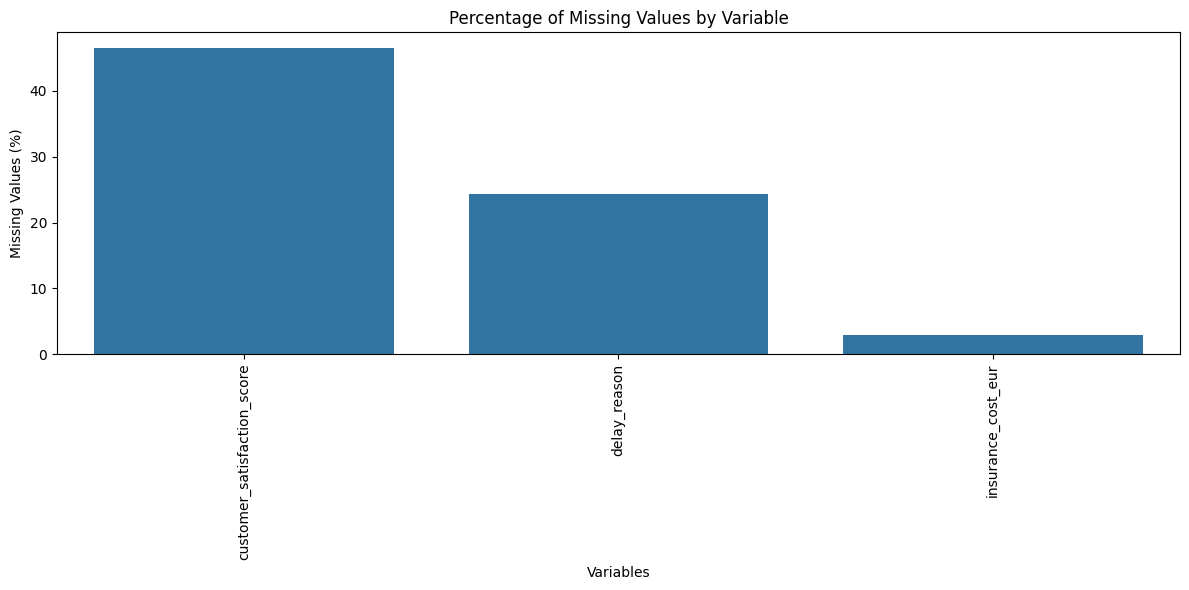

In [35]:

# visualize missing values by column

missing_data = missing_summary[
    missing_summary["Missing Values"] > 0
]

plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_data.index,
    y=missing_data["Missing Percentage"]
)

plt.xticks(rotation=90)
plt.ylabel("Missing Values (%)")
plt.xlabel("Variables")
plt.title("Percentage of Missing Values by Variable")
plt.tight_layout()
plt.show()


In [36]:
missing_by_status = df_clean.groupby("status").agg(
    Total_Shipments=("shipment_id", "count"),
    Missing_Satisfaction=(
        "customer_satisfaction_score",
        lambda x: x.isna().sum()
    ),
    Missing_Delay_Reason=(
        "delay_reason",
        lambda x: x.isna().sum()
    ),
    Missing_Insurance_Cost=(
        "insurance_cost_eur",
        lambda x: x.isna().sum()
    )
)

missing_by_status

,Total_Shipments,Missing_Satisfaction,Missing_Delay_Reason,Missing_Insurance_Cost
status,,,,
Attempted,5067,2376,1234,150
DELIVERED,5202,2421,1289,149
Delivered,5140,2337,1258,170
Failed,5206,2437,1239,151
In Transit,5246,2501,1244,150
Lost,5143,2448,1180,142
Out for Delivery,5174,2365,1271,156
Pending,5170,2415,1287,147
Returned,5133,2322,1296,149


## Examining Data Types

In [37]:

# Display data types

data_types = pd.DataFrame({
    "Column": df_clean.columns,
    "Data Type": df_clean.dtypes.astype(str).values,
    "Unique Values": df_clean.nunique().values
})

data_types


,Column,Data Type,Unique Values
0,shipment_id,object,51000
1,tracking_number,object,51000
2,order_id,object,50854
3,customer_id,object,49595
4,customer_name,object,400
5,shipment_type,object,7
6,carrier,object,9
7,status,object,10
8,origin_city,object,15
9,origin_country,object,4


##Investigating Date Columns

In [38]:

# Identify date columns

date_columns = [
    "pickup_date",
    "estimated_delivery_date",
    "actual_delivery_date",
    "created_at"
]

# Check which date columns exist

date_columns = [
    col for col in date_columns if col in df_clean.columns
]

# Examine sample values

for col in date_columns:
    print(f"\n{col}")
    print(df_clean[col].head())
    print("Current data type:", df_clean[col].dtype)



pickup_date
0    2025-07-07
1    2024-08-13
2    2022-02-12
3    2023-04-03
4    26-06-2024
Name: pickup_date, dtype: object
Current data type: object

estimated_delivery_date
0    2024-02-23
1    01/11/2023
2    2023-08-26
3    2025-12-28
4    2025-04-29
Name: estimated_delivery_date, dtype: object
Current data type: object

actual_delivery_date
0    25-06-2023
1    2025-12-17
2    2022-09-03
3    2022-12-16
4    2025-11-18
Name: actual_delivery_date, dtype: object
Current data type: object

created_at
0    2023-10-10 02:48:00
1    2023-06-07 04:38:00
2    2023-07-17 23:37:00
3    2023-01-08 21:43:00
4    2023-03-22 15:27:00
Name: created_at, dtype: object
Current data type: object


In [39]:
# Checking date format consistency
for col in date_columns:
    parsed = pd.to_datetime(
        df_clean[col],
        format="mixed",
        errors="coerce",
        dayfirst=False
    )

    print(f"\n{col}")
    print("Unparseable dates:", parsed.isna().sum())


pickup_date
Unparseable dates: 0

estimated_delivery_date
Unparseable dates: 0

actual_delivery_date
Unparseable dates: 0

created_at
Unparseable dates: 0


In [40]:
# Compare month-first and day-first interpretations

for col in date_columns:

    slash_dates = df_clean[
        df_clean[col].astype(str).str.contains("/", na=False)
    ][col]

    month_first = pd.to_datetime(
        slash_dates,
        format="mixed",
        dayfirst=False,
        errors="coerce"
    )

    day_first = pd.to_datetime(
        slash_dates,
        format="mixed",
        dayfirst=True,
        errors="coerce"
    )

    different = (
        month_first.notna() &
        day_first.notna() &
        (month_first != day_first)
    )

    print(f"\n{col}")
    print("Dates containing slashes:", len(slash_dates))
    print("Ambiguously interpreted dates:", different.sum())

    print(slash_dates[different].head(10))


pickup_date
Dates containing slashes: 6446
Ambiguously interpreted dates: 2364
45     02/04/2025
60     10/01/2022
86     02/03/2022
111    02/06/2023
116    11/10/2025
164    06/02/2023
176    01/12/2024
178    11/06/2022
191    11/02/2022
192    12/08/2023
Name: pickup_date, dtype: object

estimated_delivery_date
Dates containing slashes: 6416
Ambiguously interpreted dates: 2357
1      01/11/2023
30     05/07/2022
66     10/07/2024
95     05/02/2024
107    01/08/2025
147    04/05/2023
160    11/02/2022
173    11/02/2023
212    10/01/2025
215    04/08/2025
Name: estimated_delivery_date, dtype: object

actual_delivery_date
Dates containing slashes: 6372
Ambiguously interpreted dates: 2271
12     08/11/2024
43     03/10/2022
48     04/09/2025
70     09/04/2025
130    07/12/2024
144    02/01/2024
148    12/06/2025
162    03/10/2025
195    01/10/2022
203    12/10/2024
Name: actual_delivery_date, dtype: object

created_at
Dates containing slashes: 0
Ambiguously interpreted dates: 0
Series

In [41]:
# Investigate slash-formatted dates
for col in date_columns:
    slash_dates = df_clean.loc[
        df_clean[col].astype(str).str.contains("/", na=False),
        col
    ]

    print(f"\n{col}")

    if slash_dates.empty:
        print("No slash-formatted dates found.")
        continue

    parts = slash_dates.str.split("/", expand=True)

    first = pd.to_numeric(parts[0], errors="coerce")
    second = pd.to_numeric(parts[1], errors="coerce")

    print("First component greater than 12:", (first > 12).sum())
    print("Second component greater than 12:", (second > 12).sum())


pickup_date
First component greater than 12: 1971
Second component greater than 12: 1910

estimated_delivery_date
First component greater than 12: 1937
Second component greater than 12: 1909

actual_delivery_date
First component greater than 12: 1878
Second component greater than 12: 2005

created_at
No slash-formatted dates found.


In [42]:
# Examine actual delivery dates by shipment status

df_clean.groupby("status").agg(
    Total_Shipments=("shipment_id", "count"),
    Actual_Date_Count=("actual_delivery_date", "count"),
    Unique_Actual_Dates=("actual_delivery_date", "nunique")
)

,Total_Shipments,Actual_Date_Count,Unique_Actual_Dates
status,,,
Attempted,5067,5067,2403
DELIVERED,5202,5202,2474
Delivered,5140,5140,2496
Failed,5206,5206,2525
In Transit,5246,5246,2448
Lost,5143,5143,2518
Out for Delivery,5174,5174,2519
Pending,5170,5170,2468
Returned,5133,5133,2434


The actual delivery date is populated for every shipment, including shipments with statuses such as Pending, Lost, and In Transit. This may indicate inconsistencies between shipment status and delivery-date records. These values will be retained for now and investigated further during exploratory analysis.

### Date Format Investigation

The date columns **contain multiple formats, including ISO dates, hyphen-separated dates, and slash-separated dates.** Comparing day-first and month-first interpretations revealed that some slash-formatted dates are ambiguous. In addition, both date-component patterns occur within each delivery date column, suggesting that a single date convention cannot safely be applied to all records.

The three delivery date columns will remain unchanged until their formatting can be reliably standardized. The `created_at` column follows a consistent format and was converted separately.

## Invalid Values

In [43]:

# Numerical columns where negative values would be invalid

nonnegative_columns = [
    "package_weight_kg",
    "shipping_cost_eur",
    "insurance_cost_eur",
    "distance_km",
    "delivery_attempts",
    "co2_emissions_kg"
]

# Keep only columns that exist in the dataset

nonnegative_columns = [
    col for col in nonnegative_columns if col in df_clean.columns
]

# Count negative values

negative_summary = pd.DataFrame({
    "Negative Values": {
        col: (pd.to_numeric(df_clean[col], errors="coerce") < 0).sum()
        for col in nonnegative_columns
    }
})

negative_summary


,Negative Values
package_weight_kg,116
shipping_cost_eur,88
insurance_cost_eur,0
distance_km,0
delivery_attempts,0
co2_emissions_kg,0


In [44]:
# investigate negative values further

negative_records = df_clean[
    (df_clean["package_weight_kg"] < 0) |
    (df_clean["shipping_cost_eur"] < 0)
]

negative_records[
    [
        "shipment_id",
        "package_weight_kg",
        "shipping_cost_eur",
        "carrier",
        "status"
    ]
].head(20)

,shipment_id,package_weight_kg,shipping_cost_eur,carrier,status
11,SHP-202300011,20.34,-88.79,Hermes,Delivered
95,SHP-202300095,-13.60,57.20,GLS,Attempted
121,SHP-202300121,-13.24,66.85,UPS,Delivered
358,SHP-202300358,-39.94,18.77,Hermes,Delivered
1067,SHP-202301067,-0.99,46.54,UPS,DELIVERED
1522,SHP-202301522,7.31,-28.14,Deutsche Post,Delivered
1539,SHP-202301539,-35.51,79.61,DPD,Pending
1958,SHP-202301958,26.48,-41.61,DPD,Attempted
2484,SHP-202302484,35.06,-6.78,GLS,Delivered
2659,SHP-202302659,25.03,-55.54,FedEx,DELIVERED


## Invalid Numerical Values

The initial assessment identified 116 negative package weights and 88 negative shipping costs. These values are not physically or financially meaningful for the shipment analysis and will be treated as invalid observations.

Rather than replacing them with zero, we will convert these values to missing values to avoid introducing misleading information.

## Potential Outliers

In [45]:

# Select numerical variables

numeric_columns = df_clean.select_dtypes(
    include=np.number
).columns

# Calculate potential outliers using the IQR method

outlier_summary = []

for col in numeric_columns:

    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_summary.append({
        "Variable": col,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": len(outliers)
    })

outlier_summary = pd.DataFrame(outlier_summary)

outlier_summary.sort_values(
    by="Potential Outliers",
    ascending=False
)


,Variable,Lower Bound,Upper Bound,Potential Outliers
7,claim_amount_eur,0.00000,0.00000,7696
3,insurance_cost_eur,-14.28000,23.80000,1013
0,package_weight_kg,-24.89625,74.93375,250
2,shipping_cost_eur,-40.02000,133.82000,220
1,declared_value_eur,-2482.48500,7495.29500,0
4,distance_km,-743.50000,2244.50000,0
5,delivery_attempts,-1.00000,7.00000,0
6,customer_satisfaction_score,-1.00000,7.00000,0
8,co2_emissions_kg,-50.26375,150.28625,0


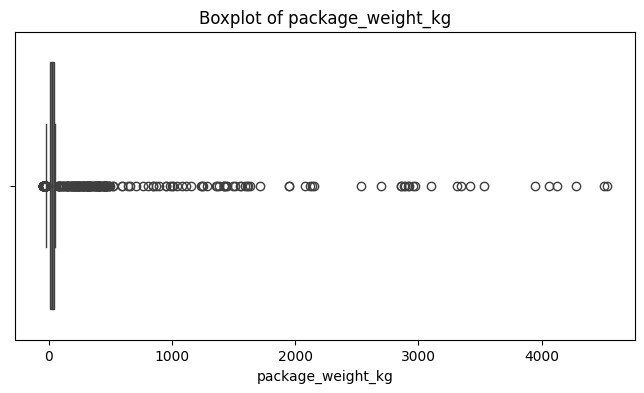

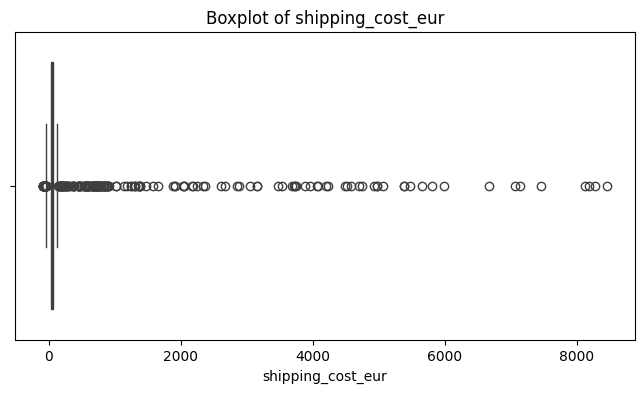

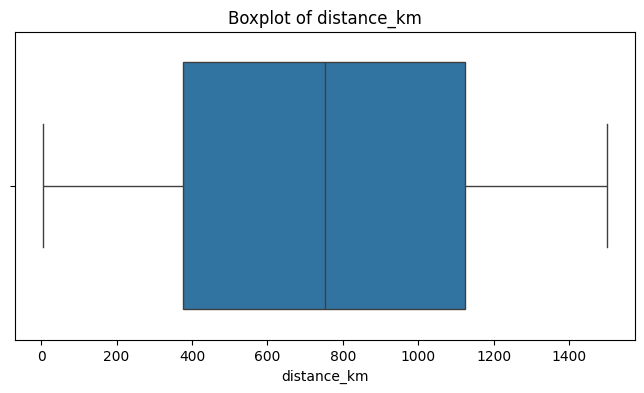

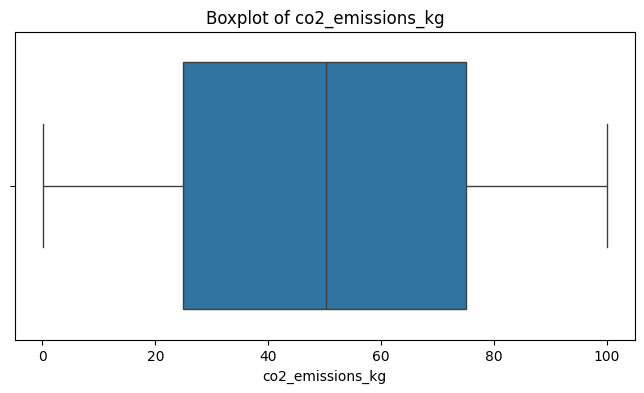

In [46]:

# Visualize selected numerical variables

columns_to_plot = [
    col for col in [
        "package_weight_kg",
        "shipping_cost_eur",
        "distance_km",
        "co2_emissions_kg"
    ]
    if col in df_clean.columns
]

for col in columns_to_plot:

    plt.figure(figsize=(8, 4))

    sns.boxplot(x=df_clean[col])

    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)

    plt.show()


Percentage of zero claims: 85.11814982403217

Positive claim amounts:
count    7696.000000
mean     2509.620151
std      1430.396563
min        50.280000
25%      1282.960000
50%      2498.955000
75%      3736.632500
max      4999.390000
Name: claim_amount_eur, dtype: float64


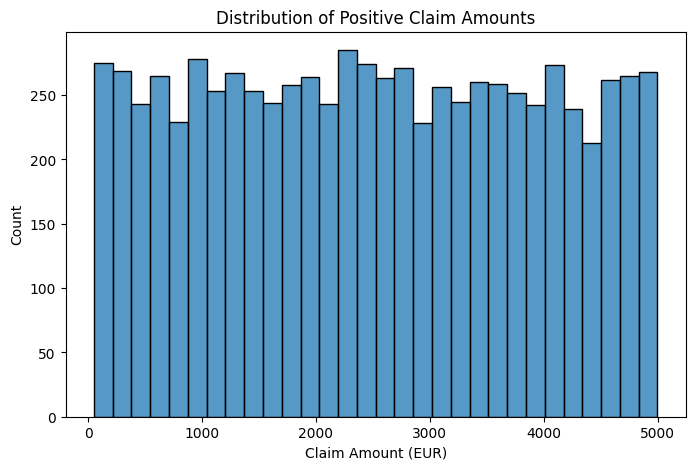

In [47]:
print("Percentage of zero claims:",
      (df_clean["claim_amount_eur"] == 0).mean() * 100)

print("\nPositive claim amounts:")
print(
    df_clean.loc[
        df_clean["claim_amount_eur"] > 0,
        "claim_amount_eur"
    ].describe()
)

plt.figure(figsize=(8, 5))

sns.histplot(
    df_clean.loc[
        df_clean["claim_amount_eur"] > 0,
        "claim_amount_eur"
    ],
    bins=30
)

plt.title("Distribution of Positive Claim Amounts")
plt.xlabel("Claim Amount (EUR)")
plt.show()

##Claim Amounts

Approximately 85.12% of shipments have a claim amount of zero. This concentration of zero values explains why the IQR method identifies a large number of potential outliers.

Since zero claim amounts may represent shipments without claims, these observations will be retained. Positive claim amounts will also be preserved for further analysis rather than automatically removing observations identified by the IQR method.

## Categorical Inconsistency

In [48]:
categorical_columns = [
    "status",
    "carrier",
    "origin_country",
    "destination_country",
    "shipment_type",
    "delay_reason"
]

for col in categorical_columns:
    print(f"\n{col}")
    print(df_clean[col].value_counts(dropna=False))


status
status
In Transit          5246
delivered           5233
Failed              5206
DELIVERED           5202
Out for Delivery    5174
Pending             5170
Lost                5143
Delivered           5140
Returned            5133
Attempted           5067
Name: count, dtype: int64

carrier
carrier
Deutsche Post       5863
GLS                 5810
DPD                 5783
Hermes              5780
FedEx               5775
DB Schenker         5732
UPS                 5687
DHL                 5684
Amazon Logistics    5600
Name: count, dtype: int64

origin_country
origin_country
GERMANY        13069
DE             12985
Germany        12904
Deutschland    12756
Name: count, dtype: int64

destination_country
destination_country
CH                3565
Austria           3523
Germany           3516
CZ                3499
GERMANY           3489
DE                3474
NL                3436
PL                3435
France            3421
Switzerland       3412
Czech Republic    3411
Poland

##Categorical Inconsistencies

The categorical assessment identified inconsistent representations of shipment statuses and country names. For example, delivered shipments appear with different capitalization, while Germany is represented using multiple names and country codes.

These inconsistencies will be standardized to ensure accurate grouping and comparisons during exploratory data analysis.

## Package Dimensions

In [49]:
dimensions = (
    df_clean["package_dimensions_cm"]
    .astype(str)
    .str.split("x", expand=True)
)

print("Number of dimension components:")
print(dimensions.shape[1])

print("\nMissing components:")
print(dimensions.isna().sum())

print("\nNon-numeric components:")
for col in dimensions.columns:
    print(
        col,
        pd.to_numeric(dimensions[col], errors="coerce").isna().sum()
    )

Number of dimension components:
3

Missing components:
0    0
1    0
2    0
dtype: int64

Non-numeric components:
0 0
1 0
2 0


## Data Cleaning Decisions

Based on the initial data quality assessment, several cleaning actions were identified and implemented.

Completely duplicated records were removed after confirming that repeated shipment IDs contained no conflicting information. Shipment statuses and country names were standardized to ensure consistency across categorical variables.

Negative values identified in package weight and shipping costs were treated as missing values rather than replaced with zero, since these values are not physically or financially meaningful.

Missing values in customer satisfaction, delay reasons, and insurance costs were preserved because their causes require further investigation. Potential outliers, particularly in claim amounts, were also retained because they may represent legitimate shipment characteristics.

The `created_at` column was converted to datetime format. The three delivery date columns were left unchanged because their mixed and ambiguous formats require further investigation. Package dimensions were confirmed to contain three numeric components and can be separated into individual features during feature engineering.

All cleaning decisions aim to preserve meaningful information while improving the consistency and reliability of the dataset.

In [50]:

# Record original dataset dimensions

original_shape = df.shape

# 1. Remove completely duplicated rows

df_clean = df_clean.drop_duplicates()

print("Duplicate rows removed:", original_shape[0] - len(df_clean))


# 2. Standardize shipment status capitalization

df_clean["status"] = (
    df_clean["status"].str.strip().str.title()
)


# 3. Standardize country names

country_mapping = {
    "germany": "Germany",
    "deutschland": "Germany",
    "de": "Germany",
    "austria": "Austria",
    "at": "Austria",
    "switzerland": "Switzerland",
    "ch": "Switzerland",
    "czech republic": "Czech Republic",
    "cz": "Czech Republic",
    "netherlands": "Netherlands",
    "nl": "Netherlands",
    "poland": "Poland",
    "pl": "Poland",
    "france": "France",
    "fr": "France"
}

for col in ["origin_country", "destination_country"]:

    df_clean[col] = df_clean[col].apply(
        lambda x: country_mapping.get(
            x.strip().casefold(), x.strip()
        ) if isinstance(x, str) else x
    )


# 4. Handle invalid negative values

invalid_columns = [
    "package_weight_kg",
    "shipping_cost_eur"
]

for col in invalid_columns:

    invalid_count = (df_clean[col] < 0).sum()

    df_clean.loc[df_clean[col] < 0, col] = np.nan

    print(f"Invalid values converted to missing in {col}: {invalid_count}")


print("\nUpdated dataset information:")
df_clean.info()


Duplicate rows removed: 714
Invalid values converted to missing in package_weight_kg: 115
Invalid values converted to missing in shipping_cost_eur: 87

Updated dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 51000 entries, 0 to 50999
Data columns (total 33 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   shipment_id                  51000 non-null  object 
 1   tracking_number              51000 non-null  object 
 2   order_id                     51000 non-null  object 
 3   customer_id                  51000 non-null  object 
 4   customer_name                51000 non-null  object 
 5   shipment_type                51000 non-null  object 
 6   carrier                      51000 non-null  object 
 7   status                       51000 non-null  object 
 8   origin_city                  51000 non-null  object 
 9   origin_country               51000 non-null  object 
 10  destination_ci

In [51]:
# Convert created_at to datetime

df_clean["created_at"] = pd.to_datetime(
    df_clean["created_at"],
    format="%Y-%m-%d %H:%M:%S",
    errors="coerce"
)

print("created_at data type:", df_clean["created_at"].dtype)
print("Missing created_at values:", df_clean["created_at"].isna().sum())

created_at data type: datetime64[ns]
Missing created_at values: 0


## Validate

In [52]:

# Compare original and cleaned dataset dimensions

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)


# Check duplicate records

print("\nRemaining duplicate rows:", df_clean.duplicated().sum())

print(
    "Remaining duplicate shipment IDs:",
    df_clean["shipment_id"].duplicated().sum()
)


# Check for remaining negative values

print("\nRemaining negative values:")

for col in ["package_weight_kg", "shipping_cost_eur"]:
    print(col, (df_clean[col] < 0).sum())


# Check standardized shipment statuses

print("\nShipment statuses:")
print(df_clean["status"].value_counts())


# Check standardized countries

print("\nOrigin countries:")
print(df_clean["origin_country"].value_counts())

print("\nDestination countries:")
print(df_clean["destination_country"].value_counts())


# Review missing values

print("\nMissing values after cleaning:")

print(
    df_clean.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)


# Review data types

df_clean.info()

print("\nDate column data types:")
print(df_clean[
    ["pickup_date", "estimated_delivery_date",
     "actual_delivery_date", "created_at"]
].dtypes)


Original dataset shape: (51714, 33)
Cleaned dataset shape: (51000, 33)

Remaining duplicate rows: 0
Remaining duplicate shipment IDs: 0

Remaining negative values:
package_weight_kg 0
shipping_cost_eur 0

Shipment statuses:
status
Delivered           15374
In Transit           5173
Failed               5136
Pending              5098
Out For Delivery     5096
Lost                 5073
Returned             5060
Attempted            4990
Name: count, dtype: int64

Origin countries:
origin_country
Germany    51000
Name: count, dtype: int64

Destination countries:
destination_country
Germany           10359
Switzerland        6875
Czech Republic     6810
Austria            6802
Poland             6732
Netherlands        6730
France             6692
Name: count, dtype: int64

Missing values after cleaning:
customer_satisfaction_score    23765
delay_reason                   12408
insurance_cost_eur              1498
package_weight_kg                115
shipping_cost_eur                 87
shi

In [53]:

# Create directory for processed data

processed_dir = "/content/drive/MyDrive/INSY_6500/data/processed"

os.makedirs(processed_dir, exist_ok=True)

# Save cleaned dataset

pickle_path = os.path.join(
    processed_dir,
    "cleaned_data.pkl"
)

df_clean.to_pickle(pickle_path)

print("Cleaned dataset saved successfully!")
print(pickle_path)


Cleaned dataset saved successfully!
/content/drive/MyDrive/INSY_6500/data/processed/cleaned_data.pkl
